<a href="https://colab.research.google.com/github/LauritoFarias/tpi-analisis-de-datos/blob/feature%2Feda-ignacio/notebooks/TPI_Analisis_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Integrador: Análisis de Churn en Telecomunicaciones (Telco)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LauritoFarias/tpi-analisis-de-datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)

**Materia:** Análisis de Datos

**Dataset:** Telco Customer Churn (Kaggle)

# A. Fundamentos, Ingesta y Limpieza de Datos

## 1. Configuración e Ingesta de Datos
* **Objetivo de negocio:** Identificar patrones de cancelación (*Churn*) en clientes de telecomunicaciones para reducir la tasa de baja.
* **Variables objetivo:** `Churn` (clasificación/fuga) y `TotalCharges` (regresión).
* **Hipótesis principales:** Mayor propensión de baja en contratos mensuales ($H_1$), en los primeros 6 meses de antigüedad ($H_2$) y en planes de Fibra Óptica con cargos elevados sin servicios de soporte ($H_3$). *(Ver desarrollo completo en `docs/INFORME_EJECUTIVO.pdf`).*

A continuación, se importan las bibliotecas y se realiza la ingesta directa del dataset estructurado (`.csv`).

In [1]:
# =============================================================================
# 1. CONFIGURACIÓN DEL ENTORNO E INGESTA DE DATOS
# =============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style="whitegrid", palette="muted")

RUTA_LOCAL = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

URL_GITHUB = "https://raw.githubusercontent.com/LauritoFarias/tpi-analisis-de-datos/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

if os.path.exists(RUTA_LOCAL):
    print(f"Cargando dataset desde entorno local: {RUTA_LOCAL}")
    df_raw = pd.read_csv(RUTA_LOCAL)
else:
    print("Entorno en la nube detectado (Colab). Cargando dataset desde GitHub...")
    df_raw = pd.read_csv(URL_GITHUB)

df = df_raw.copy()

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
display(df.head(3))

Entorno en la nube detectado (Colab). Cargando dataset desde GitHub...
Dimensiones del dataset: 7043 filas y 21 columnas.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Relevamiento de Variables vs. Tipos en Pandas (`dtypes`)
Se genera una tabla de auditoría para contrastar la clasificación estadística teórica de los 21 atributos frente a los tipos de datos asignados por defecto en Pandas (`dtypes`), identificando inconsistencias de tipado previo a la limpieza.

In [2]:
# =============================================================================
# 2. RELEVAMIENTO DE VARIABLES: CLASIFICACIÓN TEÓRICA VS PANDAS DTYPES
# =============================================================================

clasificacion_teorica = {
    'customerID': ('Cualitativa Nominal (Identificador)', 'Irrelevante para modelado'),
    'gender': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'SeniorCitizen': ('Cualitativa Nominal (Dicotómica: 0/1)', 'Explicativa'),
    'Partner': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'Dependents': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'tenure': ('Cuantitativa Discreta (Meses)', 'Explicativa'),
    'PhoneService': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'MultipleLines': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'InternetService': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'OnlineSecurity': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'OnlineBackup': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'DeviceProtection': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'TechSupport': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'StreamingTV': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'StreamingMovies': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'Contract': ('Cualitativa Ordinal (Mensual < 1 Año < 2 Años)', 'Explicativa'),
    'PaperlessBilling': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'PaymentMethod': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'MonthlyCharges': ('Cuantitativa Continua (Monetaria)', 'Explicativa'),
    'TotalCharges': ('Cuantitativa Continua (Monetaria)', 'Explicativa'),
    'Churn': ('Cualitativa Nominal (Dicotómica)', 'Variable Objetivo (Target)')
}

relevamiento_df = pd.DataFrame({
    'Columna': df.columns,
    'Tipo en Pandas (dtype)': df.dtypes.values,
    'Valores Nulos (NaN)': df.isnull().sum().values,
    'Valores Únicos': [df[col].nunique() for col in df.columns],
    'Clasificación Estadística Teórica': [clasificacion_teorica[col][0] for col in df.columns],
    'Rol en el Análisis': [clasificacion_teorica[col][1] for col in df.columns]
})

display(relevamiento_df)

,Columna,Tipo en Pandas (dtype),Valores Nulos (NaN),Valores Únicos,Clasificación Estadística Teórica,Rol en el Análisis
0,customerID,object,0,7043,Cualitativa Nominal (Identificador),Irrelevante para modelado
1,gender,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
2,SeniorCitizen,int64,0,2,Cualitativa Nominal (Dicotómica: 0/1),Explicativa
3,Partner,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
4,Dependents,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
5,tenure,int64,0,73,Cuantitativa Discreta (Meses),Explicativa
6,PhoneService,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
7,MultipleLines,object,0,3,Cualitativa Nominal (Politómica),Explicativa
8,InternetService,object,0,3,Cualitativa Nominal (Politómica),Explicativa
9,OnlineSecurity,object,0,3,Cualitativa Nominal (Politómica),Explicativa


## 3. Limpieza de Datos y Adecuación de Tipos
En este bloque se sanea la calidad del dataset ejecutando tres acciones:
1. **Detección de cadenas anómalas:** Se identifican 11 registros con espacios vacíos (`" "`) en `TotalCharges`.
2. **Imputación fundamentada:** Al verificarse que corresponden a clientes nuevos con antigüedad `tenure == 0`, se convierten a numérico (`float64`) e imputan con `0.0`.
3. **Conversión de `dtypes`:** Se recodifica `SeniorCitizen` a `Yes`/`No` y se transforman las variables cualitativas al tipo `category` (definiendo jerarquía ordinal para `Contract`).

In [3]:
# =============================================================================
# 3. LIMPIEZA DE DATOS, CADENAS ANÓMALAS Y ADECUACIÓN DE DTYPES
# =============================================================================

print("--- Auditoría de espacios en blanco (' ') ---")
for col in df.select_dtypes(include='object').columns:
    espacios = (df[col].str.strip() == "").sum()
    if espacios > 0:
        print(f"Columna '{col}': {espacios} registros con cadenas vacías.")

casos_anomalos = df[df['TotalCharges'].str.strip() == ""]
print("\nVerificación de antigüedad (tenure) en registros con TotalCharges vacío:")
display(casos_anomalos[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'}).astype('category')

orden_contratos = pd.CategoricalDtype(categories=['Month-to-month', 'One year', 'Two year'], ordered=True)
df['Contract'] = df['Contract'].astype(orden_contratos)

cols_categoricas = [col for col in df.select_dtypes(include='object').columns if col != 'customerID']
for col in cols_categoricas:
    df[col] = df[col].astype('category')

print("\n--- Verificación de dtypes tras la adecuación ---")
print(df.dtypes)
print(f"\nTotal de valores nulos remanentes en el dataset: {df.isnull().sum().sum()}")

--- Auditoría de espacios en blanco (' ') ---
Columna 'TotalCharges': 11 registros con cadenas vacías.

Verificación de antigüedad (tenure) en registros con TotalCharges vacío:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



--- Verificación de dtypes tras la adecuación ---
customerID            object
gender              category
SeniorCitizen       category
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
Churn               category
dtype: object

Total de valores nulos remanentes en el dataset: 0


## 4. Detección de Valores Atípicos (Método IQR)
Se calculan los límites del Rango Intercuartílico ($Q_1 - 1.5 \times \text{IQR}$ y $Q_3 + 1.5 \times \text{IQR}$) y se grafican los *Boxplots* para las variables numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`). Al no registrarse valores fuera de los umbrales teóricos (0% outliers), se conserva la totalidad de los registros.

,Variable,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Límite Inferior,Límite Superior,Cant. Outliers,% Outliers
0,tenure,9.00,29.00,55.00,46.00,-60.00,124.00,0,0.00
1,MonthlyCharges,35.50,70.35,89.85,54.35,-46.02,171.38,0,0.00
2,TotalCharges,398.55,1394.55,3786.60,3388.05,-4683.52,8868.67,0,0.00


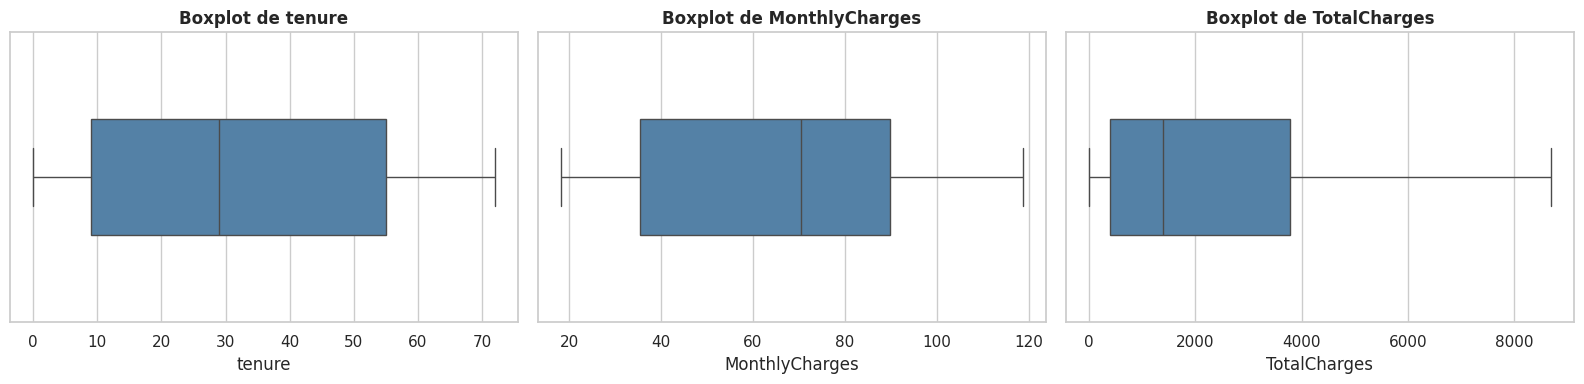

In [4]:
# =============================================================================
# 4. DETECCIÓN ANALÍTICA Y VISUAL DE VALORES ATÍPICOS (MÉTODO IQR)
# =============================================================================

variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

resumen_iqr = []

for col in variables_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]

    resumen_iqr.append({
        'Variable': col,
        'Q1 (25%)': Q1,
        'Mediana (50%)': df[col].median(),
        'Q3 (75%)': Q3,
        'IQR': IQR,
        'Límite Inferior': limite_inferior,
        'Límite Superior': limite_superior,
        'Cant. Outliers': len(outliers),
        '% Outliers': (len(outliers) / len(df)) * 100
    })

df_iqr = pd.DataFrame(resumen_iqr)
display(df_iqr)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(variables_numericas):
    sns.boxplot(x=df[col], ax=axes[i], color='steelblue', width=0.4)
    axes[i].set_title(f'Boxplot de {col}', fontweight='bold')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

## 5. Manipulación de Datos: Transformación, Filtrado y Agregación

Con el dataset limpio y tipificado, se ejecutan las operaciones requeridas de manipulación en Pandas:
* **Transformación:** Eliminación del identificador irrelevante (`customerID`), creación de columnas calculadas (`TheoreticalTotalCharges`, `BillingVariance`, `AvgHistoricalMonthlyCharge`) y demostración de renombrado de atributos.
* **Filtrado avanzado:** Aislamiento del segmento crítico de fuga combinando condiciones lógicas.
* **Agregación (`groupby`):** Resumen estadístico multidimensional (conteo, suma, media, mediana y tasa de *Churn*) segmentado por tipo de contrato y servicio de internet.

In [5]:
# =============================================================================
# 4. MANIPULACIÓN DE DATOS: TRANSFORMACIÓN, FILTRADO Y AGREGACIÓN
# =============================================================================

if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

df['TheoreticalTotalCharges'] = df['tenure'] * df['MonthlyCharges']
df['BillingVariance'] = df['TotalCharges'] - df['TheoreticalTotalCharges']

df['AvgHistoricalMonthlyCharge'] = np.where(
    df['tenure'] > 0,
    df['TotalCharges'] / df['tenure'],
    df['MonthlyCharges']
)

df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

df.rename(columns={
    'tenure': 'TenureMonths',
    'SeniorCitizen': 'IsSeniorCitizen'
}, inplace=True)
display(df[['TenureMonths', 'MonthlyCharges', 'TotalCharges', 'TheoreticalTotalCharges', 'BillingVariance']].head())

filtro_alto_riesgo = (
    (df['Contract'] == 'Month-to-month') &
    (df['InternetService'] == 'Fiber optic') &
    ((df['MonthlyCharges'] > 70) | (df['TenureMonths'] < 6)) &
    (df['Churn'] == 'Yes')
)

df_segmento_critico = df[filtro_alto_riesgo]
print(f"Clientes en el segmento crítico filtrado: {len(df_segmento_critico)} ({len(df_segmento_critico)/len(df)*100:.2f}% del total)")
display(df_segmento_critico[['IsSeniorCitizen', 'TenureMonths', 'InternetService', 'Contract', 'MonthlyCharges', 'TotalCharges']].head())

resumen_negocio = df.groupby(['Contract', 'InternetService'], observed=False).agg(
    Total_Clientes=('Churn', 'count'),
    Clientes_Perdidos=('Churn_Binary', 'sum'),
    Tasa_Churn_Pct=('Churn_Binary', lambda x: round(x.mean() * 100, 2)),
    Antiguedad_Promedio_Meses=('TenureMonths', 'mean'),
    Cargo_Mensual_Promedio=('MonthlyCharges', 'mean'),
    Cargo_Mensual_Mediana=('MonthlyCharges', 'median'),
    Facturacion_Total_Acumulada=('TotalCharges', 'sum')
).reset_index()

print("\n--- Segmentación Estratégica por Contrato y Servicio de Internet ---")
display(resumen_negocio)

,TenureMonths,MonthlyCharges,TotalCharges,TheoreticalTotalCharges,BillingVariance
0,1,29.85,29.85,29.85,0.00
1,34,56.95,1889.50,1936.30,-46.80
2,2,53.85,108.15,107.70,0.45
3,45,42.30,1840.75,1903.50,-62.75
4,2,70.70,151.65,141.40,10.25


Clientes en el segmento crítico filtrado: 1148 (16.30% del total)


,IsSeniorCitizen,TenureMonths,InternetService,Contract,MonthlyCharges,TotalCharges
4,No,2,Fiber optic,Month-to-month,70.70,151.65
5,No,8,Fiber optic,Month-to-month,99.65,820.50
8,No,28,Fiber optic,Month-to-month,104.80,3046.05
13,No,49,Fiber optic,Month-to-month,103.70,5036.30
26,No,47,Fiber optic,Month-to-month,99.35,4749.15



--- Segmentación Estratégica por Contrato y Servicio de Internet ---


,Contract,InternetService,Total_Clientes,Clientes_Perdidos,Tasa_Churn_Pct,Antiguedad_Promedio_Meses,Cargo_Mensual_Promedio,Cargo_Mensual_Mediana,Facturacion_Total_Acumulada
0,Month-to-month,DSL,1223,394,32.22,15.73,50.22,50.20,1015136.20
1,Month-to-month,Fiber optic,2128,1162,54.61,21.55,87.02,86.00,4191552.55
2,Month-to-month,No,524,99,18.89,9.13,20.41,20.05,99172.75
3,One year,DSL,570,53,9.30,40.49,61.40,61.05,1439990.85
4,One year,Fiber optic,539,104,19.29,52.10,98.78,100.15,2800424.35
5,One year,No,364,9,2.47,29.60,20.82,20.10,226638.30
6,Two year,DSL,628,12,1.91,59.14,70.46,73.30,2666283.80
7,Two year,Fiber optic,429,31,7.23,65.18,104.57,106.30,2931646.05
8,Two year,No,638,5,0.78,48.68,21.78,20.35,685323.85


---

# B. Análisis Exploratorio, Visualización e Integración — Ignacio

**Pregunta analítica:** ¿cómo se relacionan la antigüedad, los cargos, el perfil del cliente y las condiciones de contratación con la cancelación (`Churn`)?

Se utilizan los **7.043 registros del dataset ya depurado en la sección A**. Se conservan todos los clientes y se trabaja con una copia (`df_b`) para no modificar el DataFrame que necesita la siguiente sección de modelado. Se distinguen **cantidad de clientes** de **tasa de cancelación** para no confundir grupos numerosos con grupos de mayor riesgo.

> **Nota metodológica:** los patrones encontrados muestran **asociaciones**, no demuestran causalidad. Esta base representa una fotografía de los clientes y no contiene fechas para calcular tendencias temporales.

## B.1 Preparación del análisis

Se comprueba que las variables heredadas de la sección A existan. En particular, allí se renombró `tenure` como **`TenureMonths`** y se creó **`Churn_Binary`** (`1` = canceló, `0` = no canceló). No se repite la limpieza ni se vuelve a cargar el archivo.

In [6]:
# =============================================================================
# B.1 - BASE PARA EL ANÁLISIS EXPLORATORIO
# =============================================================================
columnas_b = [
    'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Binary',
    'gender', 'IsSeniorCitizen', 'Partner', 'Dependents',
    'InternetService', 'Contract', 'PaymentMethod', 'TechSupport'
]
faltantes_b = sorted(set(columnas_b).difference(df.columns))
if faltantes_b:
    raise KeyError(f'Faltan columnas de la sección A: {faltantes_b}')

df_b = df.copy(deep=True)
variables_numericas_b = ['TenureMonths', 'MonthlyCharges', 'TotalCharges']
variables_categoricas_b = [
    'gender', 'IsSeniorCitizen', 'Partner', 'Dependents',
    'InternetService', 'Contract', 'PaymentMethod', 'TechSupport'
]

tasa_global_b = df_b['Churn_Binary'].mean() * 100
print(f'Clientes analizados: {len(df_b):,}'.replace(',', '.'))
print(f'Clientes que cancelaron: {int(df_b["Churn_Binary"].sum()):,}'.replace(',', '.'))
print(f'Tasa de cancelación general: {tasa_global_b:.2f}%')
print('Nulos en las tres variables cuantitativas:', int(df_b[variables_numericas_b].isna().sum().sum()))

Clientes analizados: 7.043
Clientes que cancelaron: 1.869
Tasa de cancelación general: 26.54%
Nulos en las tres variables cuantitativas: 0


## B.2 Estadística descriptiva de variables cuantitativas

Para **antigüedad en meses** (`TenureMonths`), **cargo mensual** (`MonthlyCharges`) e **importe total acumulado** (`TotalCharges`) se calculan medidas de tendencia central (**media y mediana**), dispersión (**desviación estándar, varianza, rango e IQR**) y posición (**cuartiles**). Comparar media con mediana permite observar asimetrías.

In [7]:
# =============================================================================
# B.2 - MEDIDAS DE TENDENCIA CENTRAL, POSICIÓN Y DISPERSIÓN
# =============================================================================
resumen_numerico_b = pd.DataFrame(index=variables_numericas_b)
resumen_numerico_b['Cantidad'] = df_b[variables_numericas_b].count()
resumen_numerico_b['Media'] = df_b[variables_numericas_b].mean()
resumen_numerico_b['Mediana'] = df_b[variables_numericas_b].median()
resumen_numerico_b['Desvío estándar'] = df_b[variables_numericas_b].std()
resumen_numerico_b['Varianza'] = df_b[variables_numericas_b].var()
resumen_numerico_b['Mínimo'] = df_b[variables_numericas_b].min()
resumen_numerico_b['Q1 (25%)'] = df_b[variables_numericas_b].quantile(0.25)
resumen_numerico_b['Q3 (75%)'] = df_b[variables_numericas_b].quantile(0.75)
resumen_numerico_b['Máximo'] = df_b[variables_numericas_b].max()
resumen_numerico_b['Rango'] = resumen_numerico_b['Máximo'] - resumen_numerico_b['Mínimo']
resumen_numerico_b['IQR'] = resumen_numerico_b['Q3 (75%)'] - resumen_numerico_b['Q1 (25%)']
print('Resumen descriptivo (cargos expresados en unidades monetarias del dataset):')
display(resumen_numerico_b.round(2))

print(
    f"Interpretación: la antigüedad mediana es "
    f"{resumen_numerico_b.loc['TenureMonths', 'Mediana']:.0f} meses; "
    f"el cargo mensual medio ({resumen_numerico_b.loc['MonthlyCharges', 'Media']:.2f}) "
    f"es inferior a su mediana ({resumen_numerico_b.loc['MonthlyCharges', 'Mediana']:.2f})."
)

Resumen descriptivo (cargos expresados en unidades monetarias del dataset):


,Cantidad,Media,Mediana,Desvío estándar,Varianza,Mínimo,Q1 (25%),Q3 (75%),Máximo,Rango,IQR
TenureMonths,7043,32.37,29.00,24.56,603.17,0.00,9.00,55.00,72.00,72.00,46.00
MonthlyCharges,7043,64.76,70.35,30.09,905.41,18.25,35.50,89.85,118.75,100.50,54.35
TotalCharges,7043,2279.73,1394.55,2266.79,5138357.17,0.00,398.55,3786.60,8684.80,8684.80,3388.05


Interpretación: la antigüedad mediana es 29 meses; el cargo mensual medio (64.76) es inferior a su mediana (70.35).


### Diferencias entre clientes que cancelaron y clientes que permanecieron

Se comparan las medias y medianas de las tres variables numéricas **por `Churn`**, sin inferir que las diferencias sean efectos causales.

In [8]:
# =============================================================================
# B.2.1 - SEGMENTACIÓN DE VARIABLES NUMÉRICAS SEGÚN CHURN
# =============================================================================
comparacion_churn_b = df_b.groupby('Churn', observed=True).agg(
    Clientes=('Churn_Binary', 'size'),
    Antiguedad_media=('TenureMonths', 'mean'),
    Antiguedad_mediana=('TenureMonths', 'median'),
    Cargo_mensual_medio=('MonthlyCharges', 'mean'),
    Cargo_mensual_mediano=('MonthlyCharges', 'median'),
    Cargo_total_medio=('TotalCharges', 'mean')
)
display(comparacion_churn_b.round(2))

bajas_b = comparacion_churn_b.loc['Yes']
activos_b = comparacion_churn_b.loc['No']
print(
    f"Los clientes que cancelaron presentan {bajas_b['Antiguedad_media']:.1f} meses "
    f"de antigüedad media, frente a {activos_b['Antiguedad_media']:.1f} de quienes "
    f"permanecieron. Su cargo mensual medio también es mayor "
    f"({bajas_b['Cargo_mensual_medio']:.2f} frente a "
    f"{activos_b['Cargo_mensual_medio']:.2f})."
)

,Clientes,Antiguedad_media,Antiguedad_mediana,Cargo_mensual_medio,Cargo_mensual_mediano,Cargo_total_medio
Churn,,,,,,
No,5174,37.57,38.00,61.27,64.43,2549.91
Yes,1869,17.98,10.00,74.44,79.65,1531.80


Los clientes que cancelaron presentan 18.0 meses de antigüedad media, frente a 37.6 de quienes permanecieron. Su cargo mensual medio también es mayor (74.44 frente a 61.27).


## B.3 Correlación de Pearson y Spearman

- **Pearson:** intensidad de la relación *lineal* entre variables numéricas.
- **Spearman:** asociación *monótona* basada en rangos, menos sensible a valores extremos.

Se muestran ambas matrices y luego un mapa de calor. Una correlación alta entre `TenureMonths` y `TotalCharges` es esperable por la naturaleza acumulada del importe total; **no implica causalidad**.

In [9]:
# =============================================================================
# B.3 - MATRICES DE CORRELACIÓN
# =============================================================================
correlacion_pearson_b = df_b[variables_numericas_b].corr(method='pearson')
correlacion_spearman_b = df_b[variables_numericas_b].corr(method='spearman')
print('Correlación de Pearson:')
display(correlacion_pearson_b.round(3))
print('Correlación de Spearman:')
display(correlacion_spearman_b.round(3))
print(
    'Relación TenureMonths–TotalCharges: '
    f'Pearson = {correlacion_pearson_b.loc["TenureMonths", "TotalCharges"]:.3f}; '
    f'Spearman = {correlacion_spearman_b.loc["TenureMonths", "TotalCharges"]:.3f}.'
)

Correlación de Pearson:


,TenureMonths,MonthlyCharges,TotalCharges
TenureMonths,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


Correlación de Spearman:


,TenureMonths,MonthlyCharges,TotalCharges
TenureMonths,1.00,0.28,0.89
MonthlyCharges,0.28,1.00,0.64
TotalCharges,0.89,0.64,1.00


Relación TenureMonths–TotalCharges: Pearson = 0.826; Spearman = 0.890.


## B.4 Frecuencias y tablas de contingencia

Se reportan **frecuencias absolutas y relativas** de variables sociodemográficas y de contratación. Las tablas de contingencia cruzan cada categoría con `Churn` y calculan la tasa **dentro de cada categoría**: clientes que cancelaron / total de clientes de esa categoría. Así se pueden comparar segmentos de diferente tamaño.

In [10]:
# =============================================================================
# B.4 - DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS
# =============================================================================
filas_frecuencias_b = []
for variable_b in variables_categoricas_b:
    conteos_b = df_b[variable_b].value_counts(dropna=False, sort=False)
    for categoria_b, n_b in conteos_b.items():
        filas_frecuencias_b.append({
            'Variable': variable_b,
            'Categoría': str(categoria_b),
            'Frecuencia absoluta': int(n_b),
            'Frecuencia relativa (%)': 100 * n_b / len(df_b)
        })
frecuencias_b = pd.DataFrame(filas_frecuencias_b)
print('Distribución de clientes por cada característica:')
display(frecuencias_b.round(2))

filas_contingencias_b = []
for variable_b in variables_categoricas_b:
    tabla_b = pd.crosstab(df_b[variable_b], df_b['Churn']).reindex(
        columns=['No', 'Yes'], fill_value=0
    )
    for categoria_b, fila_b in tabla_b.iterrows():
        total_b = int(fila_b.sum())
        filas_contingencias_b.append({
            'Variable': variable_b,
            'Categoría': str(categoria_b),
            'Sin cancelación': int(fila_b['No']),
            'Con cancelación': int(fila_b['Yes']),
            'Total': total_b,
            'Tasa Churn (%)': 100 * fila_b['Yes'] / total_b if total_b else float('nan')
        })
contingencias_b = pd.DataFrame(filas_contingencias_b)
print('Tablas de contingencia resumidas por segmento:')
display(contingencias_b.round(2))

print('\nEjemplo: tabla cruzada de tipo de contrato y estado de cancelación:')
display(pd.crosstab(df_b['Contract'], df_b['Churn'], margins=True))

Distribución de clientes por cada característica:


,Variable,Categoría,Frecuencia absoluta,Frecuencia relativa (%)
0,gender,Female,3488,49.52
1,gender,Male,3555,50.48
2,IsSeniorCitizen,No,5901,83.79
3,IsSeniorCitizen,Yes,1142,16.21
4,Partner,No,3641,51.70
5,Partner,Yes,3402,48.30
6,Dependents,No,4933,70.04
7,Dependents,Yes,2110,29.96
8,InternetService,DSL,2421,34.37
9,InternetService,Fiber optic,3096,43.96


Tablas de contingencia resumidas por segmento:


,Variable,Categoría,Sin cancelación,Con cancelación,Total,Tasa Churn (%)
0,gender,Female,2549,939,3488,26.92
1,gender,Male,2625,930,3555,26.16
2,IsSeniorCitizen,No,4508,1393,5901,23.61
3,IsSeniorCitizen,Yes,666,476,1142,41.68
4,Partner,No,2441,1200,3641,32.96
5,Partner,Yes,2733,669,3402,19.66
6,Dependents,No,3390,1543,4933,31.28
7,Dependents,Yes,1784,326,2110,15.45
8,InternetService,DSL,1962,459,2421,18.96
9,InternetService,Fiber optic,1799,1297,3096,41.89



Ejemplo: tabla cruzada de tipo de contrato y estado de cancelación:


Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


## B.5 Visualizaciones y conclusiones analíticas

### B.5.1 Histogramas con densidad (KDE)

Los histogramas permiten observar cómo se distribuyen la antigüedad y los cargos mensuales. Se superponen las dos clases de `Churn` con **densidades normalizadas por grupo** (`common_norm=False`), para comparar **la forma de las distribuciones** aunque los grupos tengan tamaños distintos; las alturas no representan cantidades absolutas de clientes.

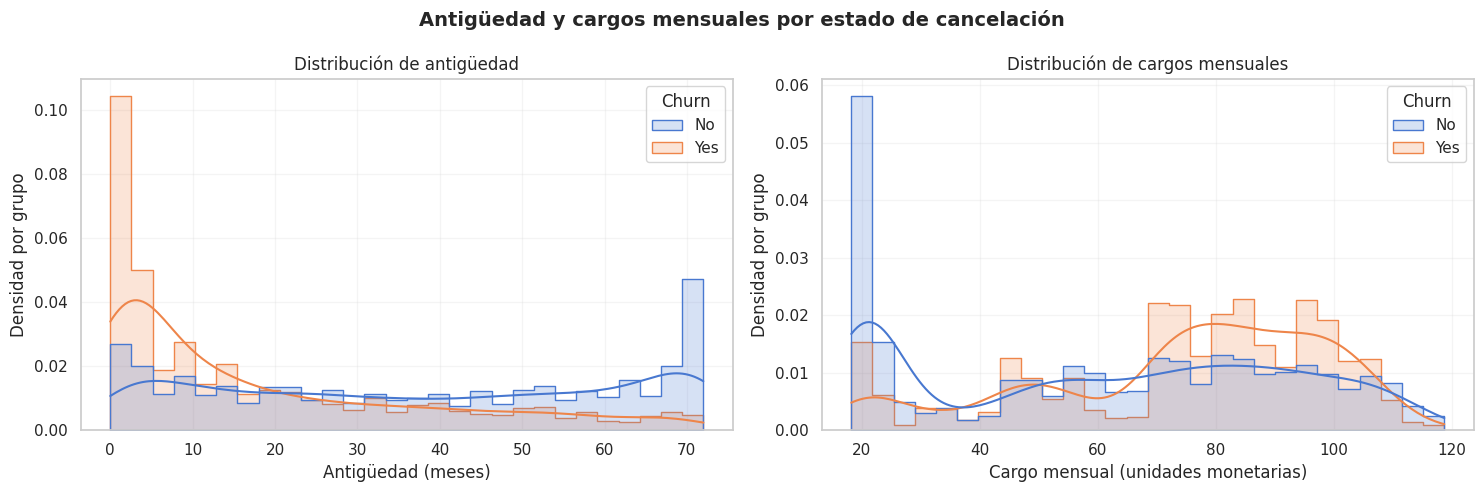

Interpretación: la distribución de los clientes que cancelaron se concentra en antigüedades menores y presenta cargos mensuales generalmente más altos. Estas distribuciones no muestran por sí mismas las tasas de cancelación por categoría.


In [11]:
# =============================================================================
# B.5.1 - HISTOGRAMAS / KDE SEGÚN CHURN
# =============================================================================
fig, ejes_b = plt.subplots(1, 2, figsize=(15, 5))
config_hist_b = [
    ('TenureMonths', 'Antigüedad (meses)', 'Distribución de antigüedad'),
    ('MonthlyCharges', 'Cargo mensual (unidades monetarias)', 'Distribución de cargos mensuales')
]
for eje_b, (variable_b, xlabel_b, titulo_b) in zip(ejes_b, config_hist_b):
    sns.histplot(
        data=df_b, x=variable_b, hue='Churn', hue_order=['No', 'Yes'],
        bins=28, kde=True, stat='density', common_norm=False,
        element='step', alpha=0.22, ax=eje_b
    )
    eje_b.set(title=titulo_b, xlabel=xlabel_b, ylabel='Densidad por grupo')
    eje_b.grid(alpha=0.2)
fig.suptitle('Antigüedad y cargos mensuales por estado de cancelación', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

print(
    'Interpretación: la distribución de los clientes que cancelaron se concentra '
    'en antigüedades menores y presenta cargos mensuales generalmente más altos. '
    'Estas distribuciones no muestran por sí mismas las tasas de cancelación por categoría.'
)

### B.5.2 Mapa de calor de correlación

El *heatmap* permite identificar visualmente qué variables monetarias están más asociadas entre sí y con la antigüedad. La escala va de -1 (asociación negativa) a +1 (positiva).

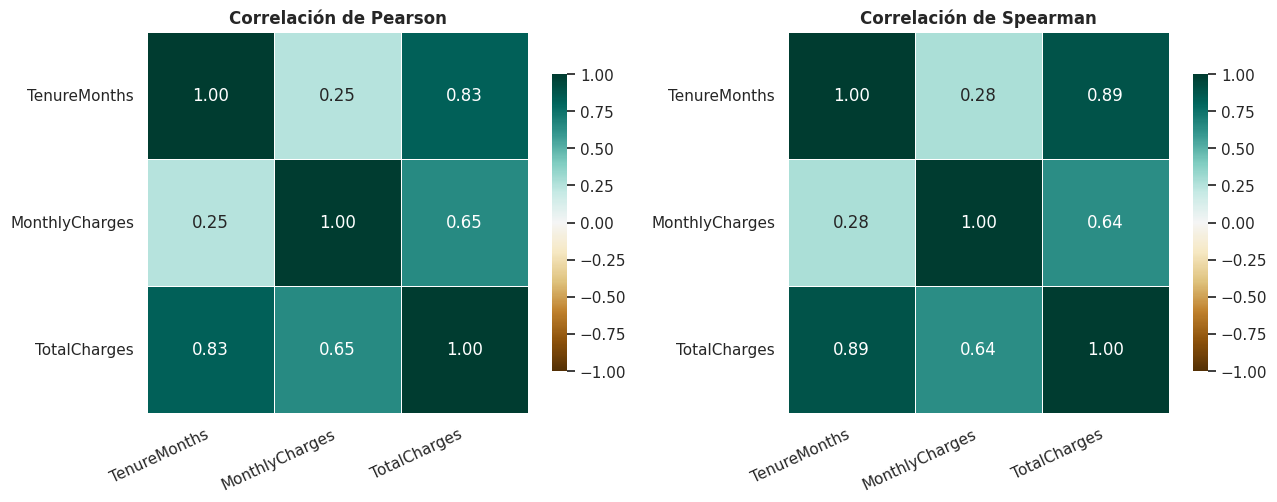

In [12]:
# =============================================================================
# B.5.2 - HEATMAP DE PEARSON Y SPEARMAN
# =============================================================================
fig, ejes_b = plt.subplots(1, 2, figsize=(13, 5))
for eje_b, matriz_b, metodo_b in zip(
    ejes_b,
    [correlacion_pearson_b, correlacion_spearman_b],
    ['Pearson', 'Spearman']
):
    sns.heatmap(
        matriz_b, annot=True, fmt='.2f', cmap='BrBG',
        vmin=-1, vmax=1, center=0, square=True, linewidths=0.6,
        cbar_kws={'shrink': 0.78}, ax=eje_b
    )
    eje_b.set_title(f'Correlación de {metodo_b}', weight='bold')
    eje_b.set_xticklabels(eje_b.get_xticklabels(), rotation=25, ha='right')
    eje_b.set_yticklabels(eje_b.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

### B.5.3 Barras comparativas: cancelación por contrato y forma de pago

Se grafica la **tasa de cancelación** (no el conteo bruto) por `Contract` y `PaymentMethod`. Cada barra incluye el número de clientes en el grupo (`n`); la línea discontinua representa la tasa general y facilita la lectura del riesgo relativo.

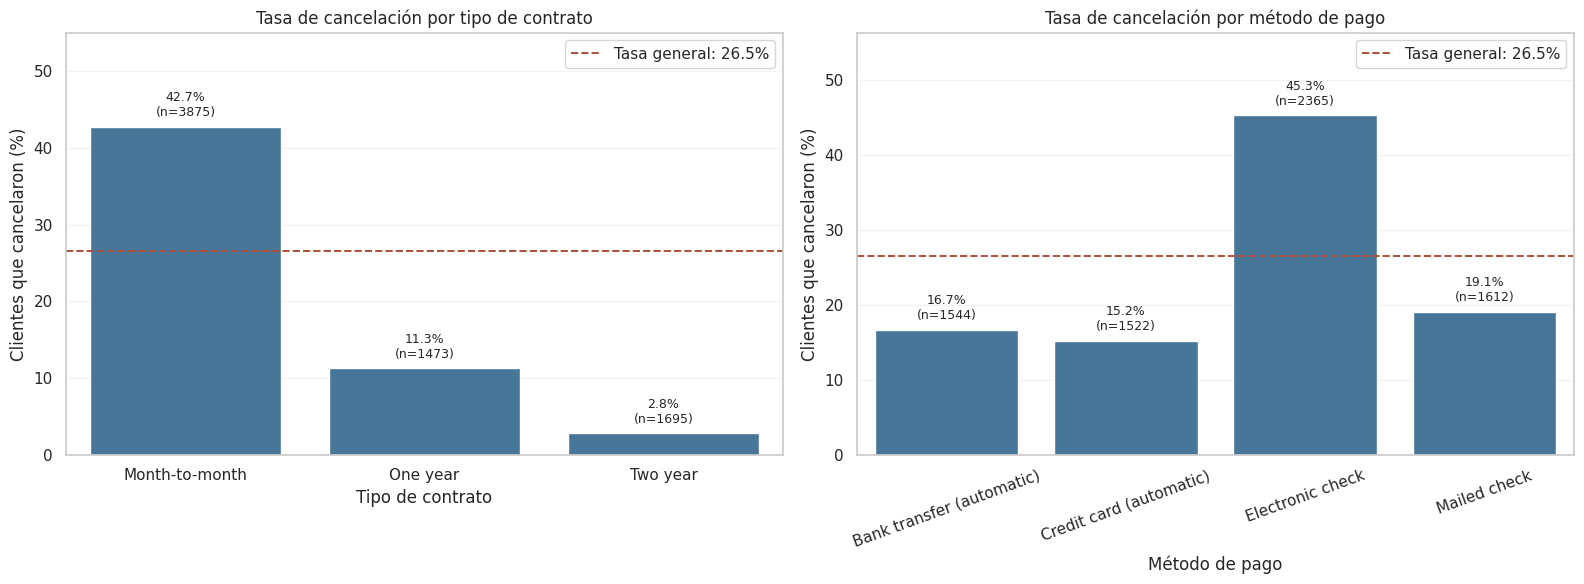

Tasas de cancelación por tipo de contrato:


,Variable,Categoría,Sin cancelación,Con cancelación,Total,Tasa Churn (%)
11,Contract,Month-to-month,2220,1655,3875,42.71
12,Contract,One year,1307,166,1473,11.27
13,Contract,Two year,1647,48,1695,2.83


Tasas de cancelación por método de pago:


,Variable,Categoría,Sin cancelación,Con cancelación,Total,Tasa Churn (%)
14,PaymentMethod,Bank transfer (automatic),1286,258,1544,16.71
15,PaymentMethod,Credit card (automatic),1290,232,1522,15.24
16,PaymentMethod,Electronic check,1294,1071,2365,45.29
17,PaymentMethod,Mailed check,1304,308,1612,19.11


In [13]:
# =============================================================================
# B.5.3 - CHURN POR TIPO DE CONTRATO Y MÉTODO DE PAGO
# =============================================================================
fig, ejes_b = plt.subplots(1, 2, figsize=(16, 6))
for eje_b, variable_b, titulo_b in zip(
    ejes_b,
    ['Contract', 'PaymentMethod'],
    ['Tipo de contrato', 'Método de pago']
):
    tasas_b = (
        df_b.groupby(variable_b, observed=True)['Churn_Binary']
        .agg(n='size', tasa='mean').reset_index()
    )
    tasas_b['tasa'] *= 100
    sns.barplot(data=tasas_b, x=variable_b, y='tasa', color='#3978a6', ax=eje_b)
    eje_b.axhline(tasa_global_b, ls='--', lw=1.4, color='#af4e35',
                   label=f'Tasa general: {tasa_global_b:.1f}%')
    eje_b.set(
        title=f'Tasa de cancelación por {titulo_b.lower()}',
        xlabel=titulo_b, ylabel='Clientes que cancelaron (%)',
        ylim=(0, max(55, tasas_b['tasa'].max() + 11))
    )
    eje_b.tick_params(axis='x', labelrotation=20 if variable_b == 'PaymentMethod' else 0)
    for i_b, fila_b in tasas_b.reset_index(drop=True).iterrows():
        eje_b.text(i_b, fila_b['tasa'] + 1, f"{fila_b['tasa']:.1f}%\n(n={int(fila_b['n'])})",
                   ha='center', va='bottom', fontsize=9)
    eje_b.legend(loc='upper right', frameon=True)
    eje_b.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print('Tasas de cancelación por tipo de contrato:')
display(contingencias_b.loc[contingencias_b['Variable'] == 'Contract'].round(2))
print('Tasas de cancelación por método de pago:')
display(contingencias_b.loc[contingencias_b['Variable'] == 'PaymentMethod'].round(2))

### B.5.4 Integración de variables: contrato × servicio de internet

El cruce de dos atributos permite revisar si la asociación con `Churn` es uniforme entre segmentos. El mapa muestra las tasas de cancelación y la tabla adjunta indica los tamaños muestrales, necesarios para interpretar cada celda con prudencia.

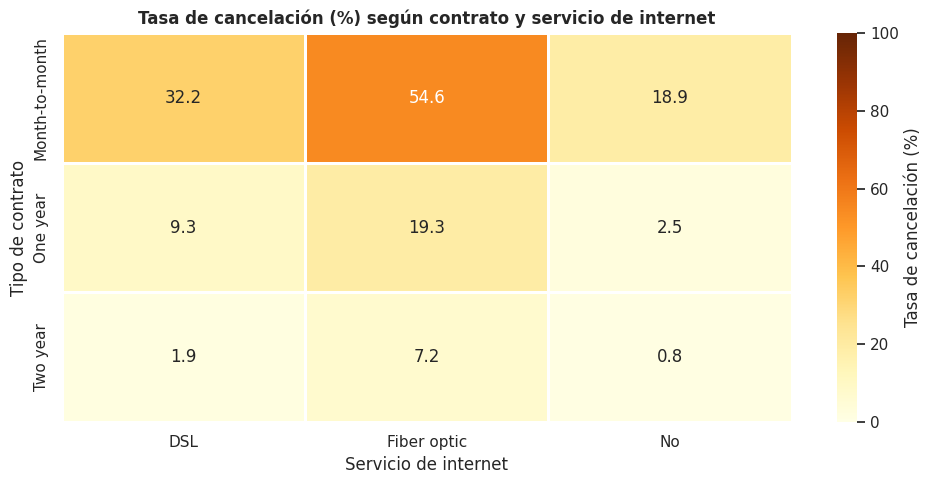

Cantidad de clientes en cada cruce:


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


In [14]:
# =============================================================================
# B.5.4 - MATRIZ DE CHURN: CONTRATO Y SERVICIO DE INTERNET
# =============================================================================
segmentos_cruzados_b = df_b.groupby(
    ['Contract', 'InternetService'], observed=True
)['Churn_Binary'].agg(n='size', tasa='mean').reset_index()
segmentos_cruzados_b['tasa'] *= 100
matriz_tasas_b = segmentos_cruzados_b.pivot(
    index='Contract', columns='InternetService', values='tasa'
)
matriz_n_b = segmentos_cruzados_b.pivot(
    index='Contract', columns='InternetService', values='n'
)

plt.figure(figsize=(10, 5))
sns.heatmap(matriz_tasas_b, annot=True, fmt='.1f', cmap='YlOrBr',
            vmin=0, vmax=100, linewidths=0.8,
            cbar_kws={'label': 'Tasa de cancelación (%)'})
plt.title('Tasa de cancelación (%) según contrato y servicio de internet', weight='bold')
plt.xlabel('Servicio de internet')
plt.ylabel('Tipo de contrato')
plt.tight_layout()
plt.show()
print('Cantidad de clientes en cada cruce:')
display(matriz_n_b)

## B.6 Hallazgos e implicancias para el negocio

1. **Cancelación total:** 1.869 de 7.043 clientes cancelaron, equivalente a **26,54 %**.
2. **Contratos:** los contratos **mes a mes** registran **42,71 %** de cancelación, frente a **11,27 %** en los anuales y **2,83 %** en los de dos años. Es razonable evaluar estrategias de fidelización y migración voluntaria a planes de mayor permanencia.
3. **Medios de pago:** **Electronic check** presenta **45,29 %** de cancelación, comparado con **15,24 %** en tarjeta de crédito automática y **16,71 %** en transferencia bancaria automática. Conviene investigar por qué sucede antes de atribuirlo al medio de pago.
4. **Antigüedad y cargos:** quienes cancelaron muestran **17,98 meses** de antigüedad media y un cargo mensual medio de **74,44**; quienes permanecieron, **37,57 meses** y **61,27**, respectivamente. La retención temprana merece un análisis específico.
5. **Segmentación conjunta:** en clientes con **contrato mes a mes y fibra óptica** la tasa observada es aproximadamente **54,6 %**. Este segmento podría priorizarse para acciones de retención, siempre validando el tamaño del grupo y la rentabilidad de las acciones.
6. **Correlación:** `TenureMonths` y `TotalCharges` presentan una asociación alta (Pearson **0,826**; Spearman **0,890**), consistente con el carácter acumulado de la facturación.

**Alcance:** se trata de un análisis descriptivo de una base de clientes; estas asociaciones no prueban que cambiar el contrato, el método de pago o el precio reduzca por sí solo la cancelación. Los modelos predictivos de la sección C podrán utilizar este análisis como insumo, evitando utilizar información derivada de la variable objetivo al predecirla.